# Predict house prices based on square footage.

In [23]:
# Step 1. Import the required libraries

import numpy as np

import pandas as pd

import seaborn as sns

import matplotlib.pyplot as plt

#Import train_test_split to divide our dataset into training and testing sets
from sklearn.model_selection import train_test_split

# Import Linear Regression to build our regression Model
from sklearn.linear_model import LinearRegression

# Import evaluation metrics to measure model performance
from sklearn.metrics import mean_squared_error, r2_score

# Import Scipy for creating a Q-Q plot to check normality
from scipy import stats

# Import warnings to keep the notebook output clean
import warnings

# Ignore unnecessary warning messages
warnings.filterwarnings('ignore')

In [9]:
#Step 2. Create a dummy dataset

In [25]:
# Set a random seed so that we get reproducible results
np.random.seed(42)

# Generate 200 house areas between 500 and 3000 square feet
area = np.random.randint(500, 3000, 200)

# Generate random noise to represent real-world price variations
noise = np.random.normal(0, 15, 200)

# Generate house prices using an underlying linear relationship
price = 50 + (0.12 * area) + noise

# Create a Pandas DataFrame containing our features and target
df = pd.DataFrame({
    "Area": area,
    "Price": price
})

# Display the first five rows to inspect our dataset
print(df.head())

# Display the dataset dimensions
print(df.shape)

# Check for missing values in each column
print(df.isnull().sum())

# Generate descriptive statistics to understand the data distribution
print(df.describe())

   Area       Price
0  1360  213.337165
1  1794  259.796911
2  1630  255.336301
3  1595  223.056897
4  2138  314.605040
(200, 2)
Area     0
Price    0
dtype: int64
              Area       Price
count   200.000000  200.000000
mean   1793.225000  267.668544
std     679.916795   84.599222
min     501.000000   91.811448
25%    1259.000000  202.831821
50%    1801.500000  267.437672
75%    2327.500000  338.162009
max    2989.000000  419.563568


Created a dataset that contains a relationship between area and price, with some random variation.

The noise is important because real-world data rarely follows a perfectly straight line.

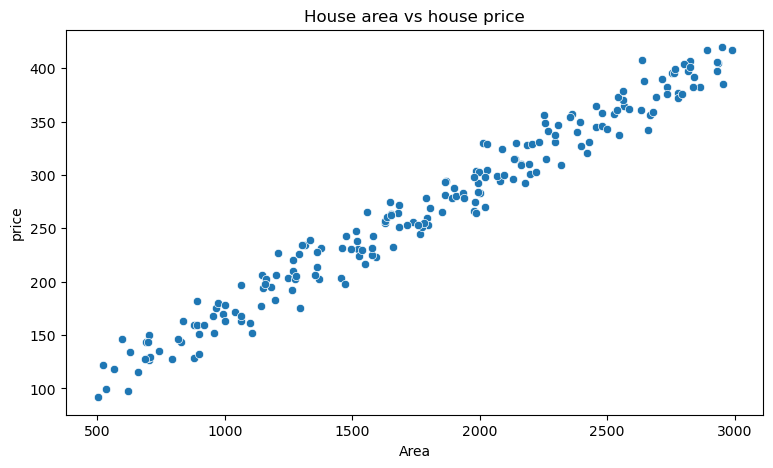

In [28]:
#Step 3. Visualise the dataset

plt.figure(figsize=(9,5))

sns.scatterplot(data=df,x='Area',y='Price')

plt.title('House area vs house price')

plt.xlabel('Area')

plt.ylabel('price')

plt.show()

### We can clearly see an upward trend, indicating a positive relationship between house area and house price.

Step 4. Separate independent and dependent variables

In [48]:
X = df[['Area']] #independent variable, provided an information to the model
y = df['Price'] # dependent variable provided the values to the model to learn and predict the price

In [52]:
y

0      213.337165
1      259.796911
2      255.336301
3      223.056897
4      314.605040
          ...    
195    274.196473
196    127.683612
197    337.337196
198    198.287620
199    364.968212
Name: Price, Length: 200, dtype: float64

Step 5. Split the data into training and testing sets

In [54]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)

print('Training model:', len(X_train))
print('Testing Model:', len(X_test))

Training model: 160
Testing Model: 40


Step 6. Create and train the Linear Regression model

In [57]:
model = LinearRegression()

model.fit(X_train,y_train)

LinearRegression()

In [59]:
intercept = model.intercept_

48.98205049622075

In [63]:
slope = model.coef_[0]
slope

0.12227546462581158

## Price = 48.9 + 0.122(Area)

Interpretation:
- Intercept: The model predicts approximately ₹48.9 lakh at zero square feet.
- Slope: Every additional square foot is associated with an increase of approximately ₹0.122 lakh in predicted price.

In [69]:
#Step 8. Make predictions
# Use the trained model to predict prices for unseen testing houses
y_pred = model.predict(X_test)

In [71]:
# crearting a comparison dataframe containing actual and predicted prices

results = pd.DataFrame({"Actual Price": y_test.values,
                        "Predicted Price": y_pred})

print(results)

    Actual Price  Predicted Price
0     361.762981       365.430953
1     329.887441       295.367112
2     143.697516       133.229846
3     296.386443       309.551066
4     251.668368       254.771657
5     229.792296       237.041715
6     391.930413       396.611196
7     176.881959       188.498356
8     314.961270       325.202325
9     281.629400       276.781241
10    168.064306       165.755119
11    278.614393       286.074176
12    278.071320       267.977408
13    169.398977       170.279311
14     97.759323       125.037389
15    262.324011       251.103394
16    283.213067       293.532980
17    194.349907       189.354284
18    294.003220       277.270343
19    247.781353       234.351655
20    372.398879       388.663291
21    397.092636       407.615988
22    254.612995       266.876928
23    330.879568       329.726517
24    234.244062       209.774286
25    115.429301       129.806133
26    356.724442       357.972150
27    250.865947       266.021000
28    292.1612

In [73]:
#Step 9. Evaluate the model using RMSE

mse = mean_squared_error(y_test,y_pred)

rmse = np.sqrt(mse)

print("RMSE:", rmse)

RMSE: 14.491511424796581


#Interpretation:

Our model's prediction errors have a root-mean-square magnitude of approximately ₹15 lakh on the test dataset.

In [76]:
#Step 10. Evaluate using R-squared

r2 = r2_score(y_test,y_pred)

print('r-square:', r2)

r-square: 0.9641405524627016


# Interpretation:

The fitted model accounts for approximately 96% of the variation in house prices in the test dataset, relative to predicting the test-set mean.

Remember: this is a measure of model performance on unseen data, not the percentage of correct predictions.

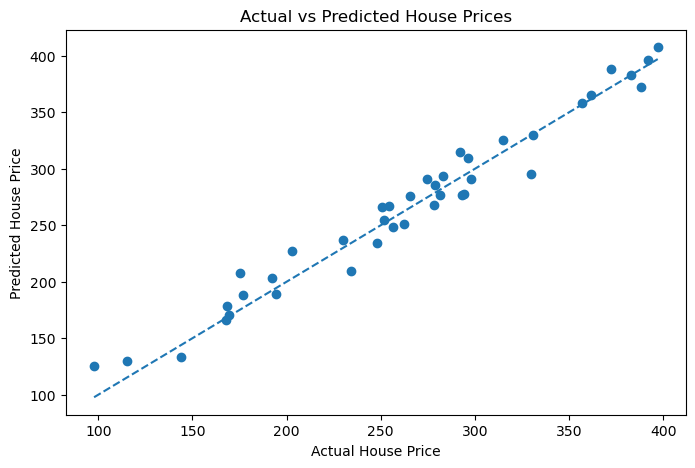

In [80]:
# Step 11 Visualize

# Create a figure for visualising actual and predicted values
plt.figure(figsize=(8, 5))

# Plot actual house prices against their predicted prices
plt.scatter(y_test, y_pred)

# Draw a reference line representing perfect predictions
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

# Label the X-axis
plt.xlabel("Actual House Price")

# Label the Y-axis
plt.ylabel("Predicted House Price")

# Add a title to the graph
plt.title("Actual vs Predicted House Prices")

# Display the graph
plt.show()

# If predictions are close to the diagonal reference line, the model is predicting accurately.

# If points are far from the line, the prediction errors are larger.